# Lab 5 – Motor parameter identification (TRIK DC motors M3 and M4)

**Name:** Yusufboy Komiljonov  
**Course / group:** CSC 413 Robotics, JAR2

**Test conditions (write here):** _robot lifted / wheels free? ..._

This notebook identifies the parameters of the two TRIK drive motors (M4 and M3) from my own measurements and checks the identified first-order model against the real motors on two complex signals (square wave and chirp).

**Runs used (all files are in `motor_data/`, exactly as the robot wrote them; columns are *angle [deg], time [ms], PWM [%]*):**

| Run | Files | What it is used for |
|---|---|---|
| Dead-zone run (PWM −9 … +9 %, 1 % steps, 2 s on + 1 s coasting per level) | `deadzone_M4.txt`, `deadzone_M3.txt` | works as a short step series: ω_ss and T_m per level, dead zone, forward/backward asymmetry |
| Square wave, ±60 % | `square_M4.txt`, `square_M3.txt` | complex signal: model identification and comparison |
| Chirp, ±60 % | `chirp_M4.txt`, `chirp_M3.txt` | second complex signal: validation and frequency response |

All blocks are built in TRIK Studio visual programming (programs in `qrs_files/`, see `README.md`).

## 1. Motor model

Neglecting the armature inductance, a lightly loaded DC motor is a first-order system in angular velocity:

$$
\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega .
$$

| Symbol | Meaning | Unit |
|---|---|---|
| $U$ | Voltage on the motor, $U=\mathrm{PWM}/100\cdot U_{battery}$ | V |
| $\theta,\ \omega$ | Shaft angle and angular velocity | rad, rad/s |
| $\omega_{ss}$ | Steady speed reached for a constant $U$ | rad/s |
| $T_m$ | Electromechanical time constant: time to reach 63 % of $\omega_{ss}$ | s |
| $k_e$ | Back-EMF constant: volts needed per rad/s of speed | V·s/rad |

**Step response.** For a constant $U$ switched on at $t=0$ from rest, $\omega(0)=0$:
the equation $T_m\dot\omega+\omega=U/k_e=\omega_{ss}$ has the solution $\omega(t)=\omega_{ss}\left(1-e^{-t/T_m}\right)$.
Integrating with $\theta(0)=0$:

$$
\theta(t)=\omega_{ss}\left[t-T_m\left(1-e^{-t/T_m}\right)\right]=\omega_{ss}\left(t-T_m+T_m e^{-t/T_m}\right).
$$

**Assumptions** (each is tested by the data below): no inductance, linear viscous friction, constant load, constant battery voltage during a run, and both directions behave the same.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

DATA = Path("motor_data")
if not DATA.is_dir():
    raise FileNotFoundError("Put this notebook beside the motor_data folder. Current folder: " + str(Path.cwd()))

# battery voltage written down for the runs
U_BAT = float((DATA / "battery.txt").read_text().split(":")[1])
print(f"U_battery = {U_BAT:.3f} V")

def load_run(name):
    raw = np.loadtxt(DATA / name, delimiter=",")       # columns: angle [deg], time [ms], PWM [%]
    return dict(name=name,
                t=(raw[:, 1] - raw[0, 1]) / 1000.0,    # s from start of file
                theta=np.deg2rad(raw[:, 0] - raw[0, 0]),  # rad from first sample
                pwm=raw[:, 2],
                t0_ms=raw[0, 1])

# inventory of every raw file in motor_data/
rows = []
for p in sorted(DATA.glob("*.txt")):
    if "battery" in p.name:
        continue
    r = load_run(p.name)
    rows.append({"file": p.name, "samples": len(r["t"]), "duration, s": round(r["t"][-1], 2),
                 "mean dt, ms": round(1000 * np.diff(r["t"]).mean(), 1),
                 "PWM min/max, %": f"{r['pwm'].min():.0f} / {r['pwm'].max():.0f}",
                 "angle change, deg": round(np.rad2deg(r["theta"][-1]), 0)})
display(pd.DataFrame(rows))

RUNS = {m: {k: load_run(f"{k}_{m}.txt") for k in ("deadzone", "square", "chirp")} for m in ("M4", "M3")}

U_battery = 11.804 V


,file,samples,"duration, s","mean dt, ms","PWM min/max, %","angle change, deg"
0,chirp_M3.txt,190,9.00,47.6,-60 / 60,229.0
1,chirp_M4.txt,187,8.99,48.4,-60 / 60,295.0
2,deadzone_M3.txt,1832,57.26,31.3,-9 / 9,-33.0
3,deadzone_M4.txt,1851,57.23,30.9,-9 / 9,78.0
4,square_M3.txt,194,8.98,46.5,-60 / 60,-46.0
5,square_M4.txt,187,8.99,48.3,-60 / 60,49.0
6,steps_M3.txt,103,2.98,29.3,0 / 0,0.0
7,steps_M4.txt,100,2.99,30.2,0 / 0,0.0
8,steps_M4_repeat.txt,95,2.97,31.6,0 / 0,0.0


## 2. Step responses from the dead-zone runs

In the dead-zone run each PWM level (−9 … +9 %) is held for 2 s and then the motor is switched off for about 1 s (coasting). The motor is almost at rest when the next level starts, so every level is a step response. I split the file by the PWM column, subtract the first angle and time of every segment and fit

$$\theta(t)=\omega_{ss}\,(t-T_m+T_m e^{-t/T_m})$$

with `optimize.curve_fit`. The standard errors come from the covariance matrix. A fit is marked *low confidence* when $T_m$ sits on a fit bound or the wheel turned less than 60°.

In [2]:
def step_model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def segments(run):
    p = run["pwm"]
    cuts = np.r_[0, np.where(np.diff(p) != 0)[0] + 1, len(p)]
    return [(int(p[a]), a, b) for a, b in zip(cuts[:-1], cuts[1:])]

T_LO, T_HI = 0.02, 2.0
def fit_level(run, a, b):
    t = run["t"][a:b] - run["t"][a]
    th = run["theta"][a:b] - run["theta"][a]
    h = len(t) // 2
    s0 = (th[-1] - th[h]) / (t[-1] - t[h])
    popt, pcov = optimize.curve_fit(step_model, t, th, p0=[s0, 0.2],
                                    bounds=([-60, T_LO], [60, T_HI]), maxfev=20000)
    err = np.sqrt(np.diag(pcov)) if np.all(np.isfinite(pcov)) else [np.nan, np.nan]
    rmse = np.sqrt(np.mean((step_model(t, *popt) - th) ** 2))
    travel = np.rad2deg(abs(th[-1]))
    bad = popt[1] < T_LO * 1.05 or popt[1] > T_HI * 0.98 or travel < 60
    return dict(t=t, theta=th, w_ss=popt[0], T_m=popt[1], w_err=err[0], T_err=err[1],
                rmse=rmse, travel=travel, ok=not bad)

FITS, STEP_DATA = {}, {}
for m in ("M4", "M3"):
    run = RUNS[m]["deadzone"]
    recs = []
    for pwm, a, b in segments(run):
        if pwm == 0:
            continue
        f = fit_level(run, a, b)
        STEP_DATA[(m, pwm)] = f
        recs.append({"PWM, %": pwm, "U, V": pwm / 100 * U_BAT, "ω_ss, rad/s": f["w_ss"], "± ω_ss": f["w_err"],
                     "T_m, s": f["T_m"], "± T_m": f["T_err"], "RMSE, rad": f["rmse"],
                     "travel, deg": f["travel"], "fit": "ok" if f["ok"] else "low confidence"})
    FITS[m] = pd.DataFrame(recs)
    print(f"Motor {m}: {len(FITS[m])} levels fitted, {(FITS[m]['fit'] != 'ok').sum()} low confidence")
    display(FITS[m].round(3))

Motor M4: 18 levels fitted, 2 low confidence


,"PWM, %","U, V","ω_ss, rad/s",± ω_ss,"T_m, s",± T_m,"RMSE, rad","travel, deg",fit
0,-9,-1.062,-3.214,0.005,0.253,0.002,0.012,316.0,ok
1,-8,-0.944,-3.290,0.007,0.263,0.002,0.015,321.0,ok
2,-7,-0.826,-3.333,0.006,0.295,0.002,0.012,320.0,ok
3,-6,-0.708,-3.289,0.012,0.358,0.004,0.020,303.0,ok
4,-5,-0.590,-2.273,0.007,0.312,0.004,0.014,217.0,ok
5,-4,-0.472,-2.193,0.006,0.430,0.003,0.008,195.0,ok
6,-3,-0.354,-3.303,0.083,0.020,0.028,0.358,337.0,low confidence
7,-2,-0.236,-2.264,0.004,0.257,0.002,0.010,223.0,ok
8,-1,-0.118,-0.682,0.614,2.000,2.356,0.083,38.0,low confidence
9,1,0.118,1.274,0.005,0.393,0.004,0.007,114.0,ok


Motor M3: 18 levels fitted, 0 low confidence


,"PWM, %","U, V","ω_ss, rad/s",± ω_ss,"T_m, s",± T_m,"RMSE, rad","travel, deg",fit
0,-9,-1.062,-4.119,0.016,0.520,0.005,0.018,345.0,ok
1,-8,-0.944,-4.236,0.011,0.513,0.003,0.012,357.0,ok
2,-7,-0.826,-4.063,0.014,0.427,0.004,0.020,359.0,ok
3,-6,-0.708,-4.153,0.006,0.440,0.002,0.009,368.0,ok
4,-5,-0.590,-2.768,0.010,0.402,0.005,0.016,248.0,ok
5,-4,-0.472,-2.876,0.009,0.618,0.004,0.008,229.0,ok
6,-3,-0.354,-2.524,0.006,0.350,0.003,0.011,230.0,ok
7,-2,-0.236,-2.582,0.011,0.345,0.005,0.020,239.0,ok
8,-1,-0.118,-1.170,0.010,0.619,0.012,0.009,91.0,ok
9,1,0.118,1.172,0.022,0.737,0.027,0.015,85.0,ok


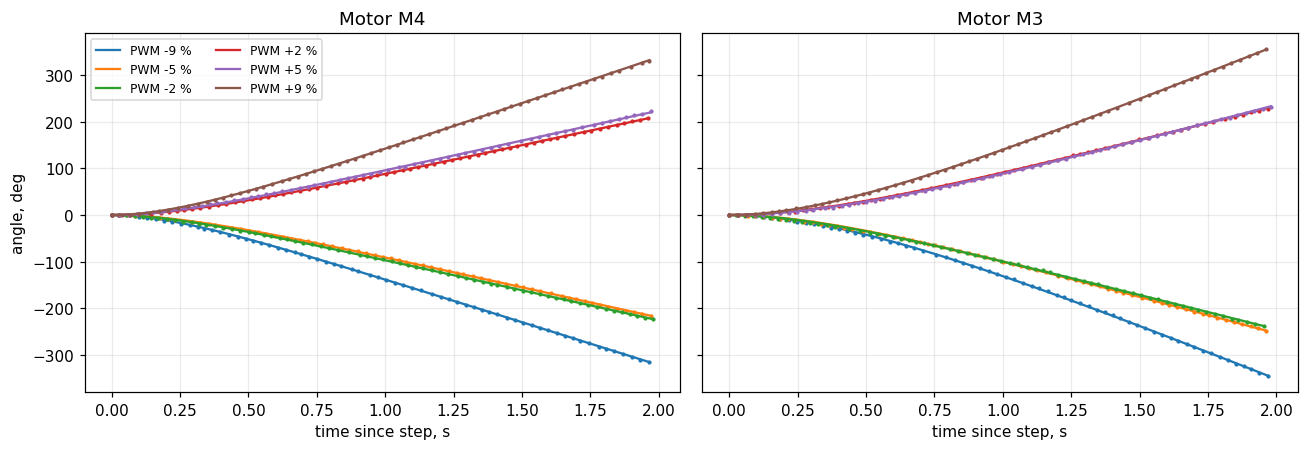

In [3]:
# Plot: step responses with the fitted model for some levels
levels = (-9, -5, -2, 2, 5, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m in zip(axes, ("M4", "M3")):
    for k, lv in enumerate(levels):
        f = STEP_DATA[(m, lv)]
        c = f"C{k}"
        ax.plot(f["t"], np.rad2deg(f["theta"]), ".", color=c, ms=3.5)
        ax.plot(f["t"], np.rad2deg(step_model(f["t"], f["w_ss"], f["T_m"])), "-", color=c, label=f"PWM {lv:+d} %")
    ax.set_title(f"Motor {m}"); ax.set_xlabel("time since step, s")
axes[0].set_ylabel("angle, deg")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

*Figure 1. Step responses θ(t) at six PWM levels for both motors. Dots are the encoder data, lines are the fitted first-order model.*

## 3. Speed and time constant versus PWM

For each direction I fit a straight line $\omega_{ss}=\text{slope}\cdot \mathrm{PWM}+b$ through the fitted levels. Since $1\,\%$ PWM equals $U_{battery}/100$ volts,

$$k_e=\frac{U_{battery}/100}{\text{slope}}\quad[\mathrm{V\,s/rad}].$$

The **dead zone** is the largest tested level at which the motor did not move (|ω_ss| ≤ 0.3 rad/s); 0 means the motor already moves at 1 %.

In [4]:
def direction_row(m, name, sign):
    d = FITS[m][np.sign(FITS[m]["PWM, %"]) == sign]
    good = d[d["fit"] == "ok"]
    slope, b = np.polyfit(good["PWM, %"], good["ω_ss, rad/s"], 1)
    moving = d[np.abs(d["ω_ss, rad/s"]) > 0.3]["PWM, %"].abs()
    dz = (moving.min() - 1) if len(moving) else d["PWM, %"].abs().max()
    return dict(Direction=name, **{"Dead zone, % PWM": float(dz), "Slope, rad/s per % PWM": slope,
                "k_e, V·s/rad": (U_BAT / 100) / slope, "Mean T_m, s": good["T_m, s"].mean(),
                "U_battery, V": U_BAT}), (slope, b)

TABLE, LINES = {}, {}
for m in ("M4", "M3"):
    r1, l1 = direction_row(m, "Forward", +1)
    r2, l2 = direction_row(m, "Backward", -1)
    TABLE[m] = pd.DataFrame([r1, r2]); LINES[m] = {"Forward": l1, "Backward": l2}
    print(f"Estimated values, motor {m}")
    display(TABLE[m].round(4))

Estimated values, motor M4


,Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
0,Forward,0.0,0.2600,0.4540,0.3079,11.8044
1,Backward,0.0,0.1915,0.6163,0.3098,11.8044


Estimated values, motor M3


,Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
0,Forward,0.0,0.3396,0.3475,0.4953,11.8044
1,Backward,0.0,0.3519,0.3355,0.4705,11.8044


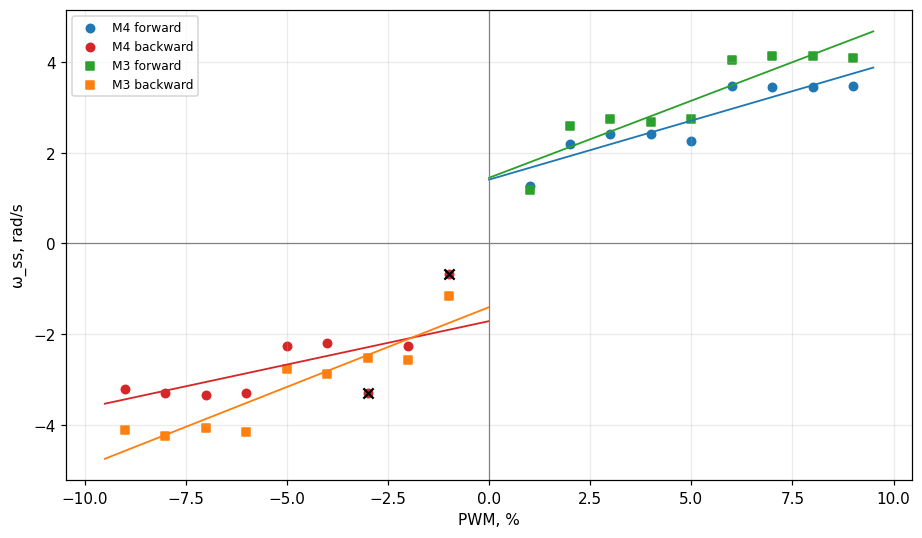

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5))
col = {("M4", "Forward"): "C0", ("M4", "Backward"): "C3", ("M3", "Forward"): "C2", ("M3", "Backward"): "C1"}
for m, mk in (("M4", "o"), ("M3", "s")):
    df = FITS[m]
    for name, sign in (("Forward", 1), ("Backward", -1)):
        d = df[np.sign(df["PWM, %"]) == sign]
        c = col[(m, name)]
        ax.scatter(d["PWM, %"], d["ω_ss, rad/s"], marker=mk, color=c, s=30, label=f"{m} {name.lower()}")
        low = d[d["fit"] != "ok"]
        ax.scatter(low["PWM, %"], low["ω_ss, rad/s"], marker="x", color="k", s=45)
        slope, b = LINES[m][name]
        x = np.linspace(0, 9.5, 20) * sign
        ax.plot(x, slope * x + b, color=c, lw=1.2)
        dz = TABLE[m].set_index("Direction").loc[name, "Dead zone, % PWM"]
        if dz > 0:
            ax.axvspan(0, dz * sign, color=c, alpha=0.12)
ax.axhline(0, color="gray", lw=.8); ax.axvline(0, color="gray", lw=.8)
ax.set_xlabel("PWM, %"); ax.set_ylabel("ω_ss, rad/s"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Figure 2. Steady speed ω_ss against PWM, forward and backward, both motors, with a straight-line fit per direction. Black crosses are low-confidence fits. A shaded band would mark a dead zone (none is visible at the 1 % resolution if no band is drawn).*

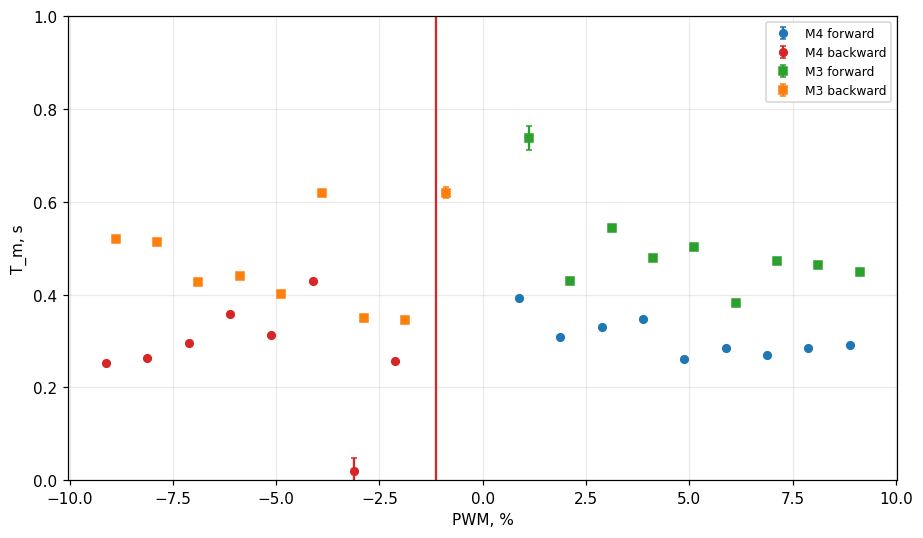

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5))
for m, mk, off in (("M4", "o", -0.12), ("M3", "s", 0.12)):
    df = FITS[m]
    for name, sign in (("Forward", 1), ("Backward", -1)):
        d = df[np.sign(df["PWM, %"]) == sign]
        ax.errorbar(d["PWM, %"] + off, d["T_m, s"], yerr=d["± T_m"], fmt=mk, ms=5, capsize=2,
                    color=col[(m, name)], label=f"{m} {name.lower()}")
ax.set_xlabel("PWM, %"); ax.set_ylabel("T_m, s"); ax.set_ylim(0, 1.0); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Figure 3. Time constant T_m against PWM with fit standard errors (error bars from the covariance matrix of `curve_fit`; points are shifted slightly sideways so that M4 and M3 do not overlap).*

## 4. Complex signals: model versus real motor

**Measured speed** = `np.gradient(angle, t)` smoothed with a moving average of **3 samples** (about 0.15 s). **Simulated motor:** the exact solution of the first-order equation, with the recorded PWM *held* (zero-order hold) between two samples, starting from rest. A dead zone is added as $u_{eff}=\mathrm{sign}(u)\,(|u|-dz)$ for $|u|>dz$, else 0.

Four parameter sets are compared for each motor:

* **A** – from the dead-zone runs only: slope = mean of the two directions, mean T_m, no dead zone;
* **B** – gain and T_m refined on the square wave (least squares on the angle), no dead zone;
* **C** – like B, with the dead zone also fitted;
* **D** – like C, fitted on square and chirp together (no independent validation).

Fit % = 100·(1 − ‖y − ŷ‖ / ‖y − mean(y)‖).

In [7]:
WIN = 3
def smooth(x, w=WIN):
    return np.convolve(x, np.ones(w) / w, mode="same")

def meas_speed(run):
    return smooth(np.gradient(run["theta"], run["t"]))

def simulate(t, pwm, gain, T_m, dz=0.0):
    # first-order model, PWM held between samples; gain in rad/s per % PWM
    th, w = 0.0, 0.0
    TH, W = [0.0], [0.0]
    for k in range(1, len(t)):
        dt = t[k] - t[k - 1]
        u = pwm[k - 1]
        ue = 0.0 if abs(u) <= dz else np.sign(u) * (abs(u) - dz)
        wss = gain * ue
        a = np.exp(-dt / T_m)
        th += wss * dt + (w - wss) * T_m * (1 - a)
        w = wss + (w - wss) * a
        TH.append(th); W.append(w)
    return np.array(TH), np.array(W)

def fit_pct(y, yh):
    return 100 * (1 - np.linalg.norm(y - yh) / np.linalg.norm(y - np.mean(y)))

def fit_params(runs, use_dz):
    def res(p):
        dz = p[2] if use_dz else 0.0
        return np.concatenate([simulate(r["t"], r["pwm"], p[0], p[1], dz)[0] - r["theta"] for r in runs])
    lo, hi = [0.001, 0.03, 0.0], [2.0, 1.0, 25.0]
    out = optimize.least_squares(res, [0.15, 0.2, 1.0], bounds=(lo, hi))
    return out.x[0], out.x[1], (out.x[2] if use_dz else 0.0)

PARAMS = {}
for m in ("M4", "M3"):
    t_ = TABLE[m]
    gA = t_["Slope, rad/s per % PWM"].abs().mean(); TA = t_["Mean T_m, s"].mean()
    sq, ch = RUNS[m]["square"], RUNS[m]["chirp"]
    PARAMS[(m, "A")] = (gA, TA, 0.0)
    PARAMS[(m, "B")] = fit_params([sq], False)
    PARAMS[(m, "C")] = fit_params([sq], True)
    PARAMS[(m, "D")] = fit_params([sq, ch], True)

def evaluate(m, key, sig):
    run = RUNS[m][sig]
    th, w = simulate(run["t"], run["pwm"], *PARAMS[(m, key)])
    return dict(rmse=np.sqrt(np.mean((th - run["theta"]) ** 2)), fit_ang=fit_pct(run["theta"], th),
                fit_spd=fit_pct(meas_speed(run), smooth(w)))

rows = []
for m in ("M4", "M3"):
    for key in "ABCD":
        g, T, dz = PARAMS[(m, key)]
        s, c = evaluate(m, key, "square"), evaluate(m, key, "chirp")
        rows.append({"Motor": m, "Set": key, "gain, rad/s per %": g, "k_e, V·s/rad": (U_BAT / 100) / g, "T_m, s": T, "dead zone, %": dz,
                     "square RMSE, rad": s["rmse"], "square fit angle, %": s["fit_ang"], "square fit speed, %": s["fit_spd"],
                     "chirp RMSE, rad": c["rmse"], "chirp fit angle, %": c["fit_ang"], "chirp fit speed, %": c["fit_spd"]})
RESULTS = pd.DataFrame(rows)
display(RESULTS.round(3))

,Motor,Set,"gain, rad/s per %","k_e, V·s/rad","T_m, s","dead zone, %","square RMSE, rad","square fit angle, %","square fit speed, %","chirp RMSE, rad","chirp fit angle, %","chirp fit speed, %"
0,M4,A,0.226,0.523,0.309,0.000,0.671,50.816,52.568,0.510,60.004,56.738
1,M4,B,0.208,0.567,0.177,0.000,0.546,59.959,70.614,0.600,52.932,69.985
2,M4,C,0.214,0.552,0.177,1.615,0.546,59.959,70.614,0.680,46.688,69.539
3,M4,D,0.223,0.530,0.180,0.000,0.586,57.006,66.200,0.388,69.541,67.812
4,M3,A,0.346,0.341,0.483,0.000,1.876,-12.487,44.039,3.915,-204.052,47.965
5,M3,B,0.209,0.565,0.161,0.000,0.450,73.030,76.352,1.172,9.002,68.791
6,M3,C,0.213,0.554,0.161,1.144,0.450,73.030,76.352,1.145,11.079,68.788
7,M3,D,0.198,0.595,0.145,2.000,0.506,69.654,80.450,0.995,22.705,68.786


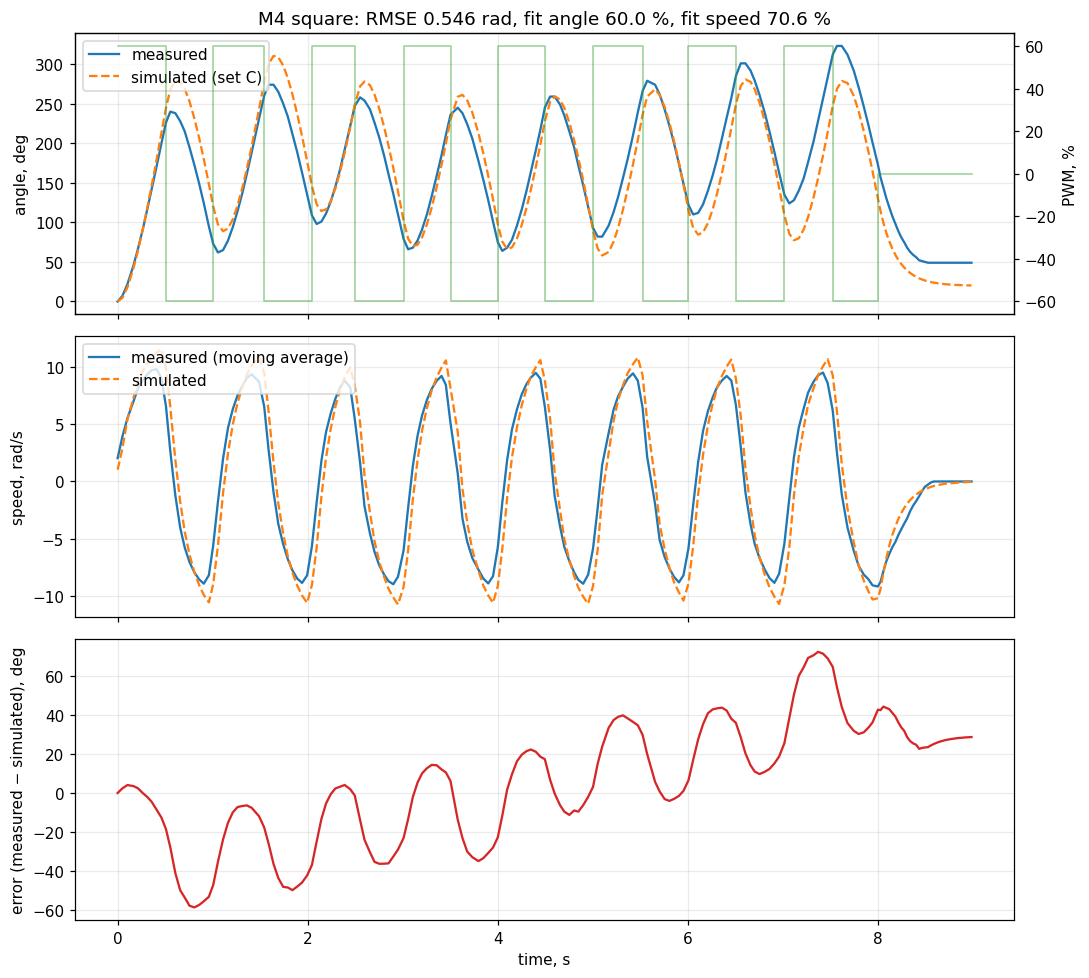

In [8]:
def plot_signal(m, sig, key):
    run = RUNS[m][sig]
    th, w = simulate(run["t"], run["pwm"], *PARAMS[(m, key)])
    ms = meas_speed(run); ss = smooth(w)
    fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    ax[0].plot(run["t"], np.rad2deg(run["theta"]), "C0", label="measured")
    ax[0].plot(run["t"], np.rad2deg(th), "C1--", label=f"simulated (set {key})")
    ax[0].set_ylabel("angle, deg"); ax[0].legend(loc="upper left")
    a2 = ax[0].twinx(); a2.step(run["t"], run["pwm"], "C2", where="post", alpha=.5, lw=1); a2.set_ylabel("PWM, %"); a2.grid(False)
    ax[1].plot(run["t"], ms, "C0", label="measured (moving average)")
    ax[1].plot(run["t"], ss, "C1--", label="simulated")
    ax[1].set_ylabel("speed, rad/s"); ax[1].legend(loc="upper left")
    ax[2].plot(run["t"], np.rad2deg(run["theta"] - th), "C3")
    ax[2].set_ylabel("error (measured − simulated), deg"); ax[2].set_xlabel("time, s")
    ev = evaluate(m, key, sig)
    ax[0].set_title(f"{m} {sig}: RMSE {ev['rmse']:.3f} rad, fit angle {ev['fit_ang']:.1f} %, fit speed {ev['fit_spd']:.1f} %")
    plt.tight_layout(); plt.show()

plot_signal("M4", "square", "C")

*Figure 4. Square wave, motor M4 (parameter set C): measured and simulated angle with the input PWM, measured and simulated speed, and the error over time.*

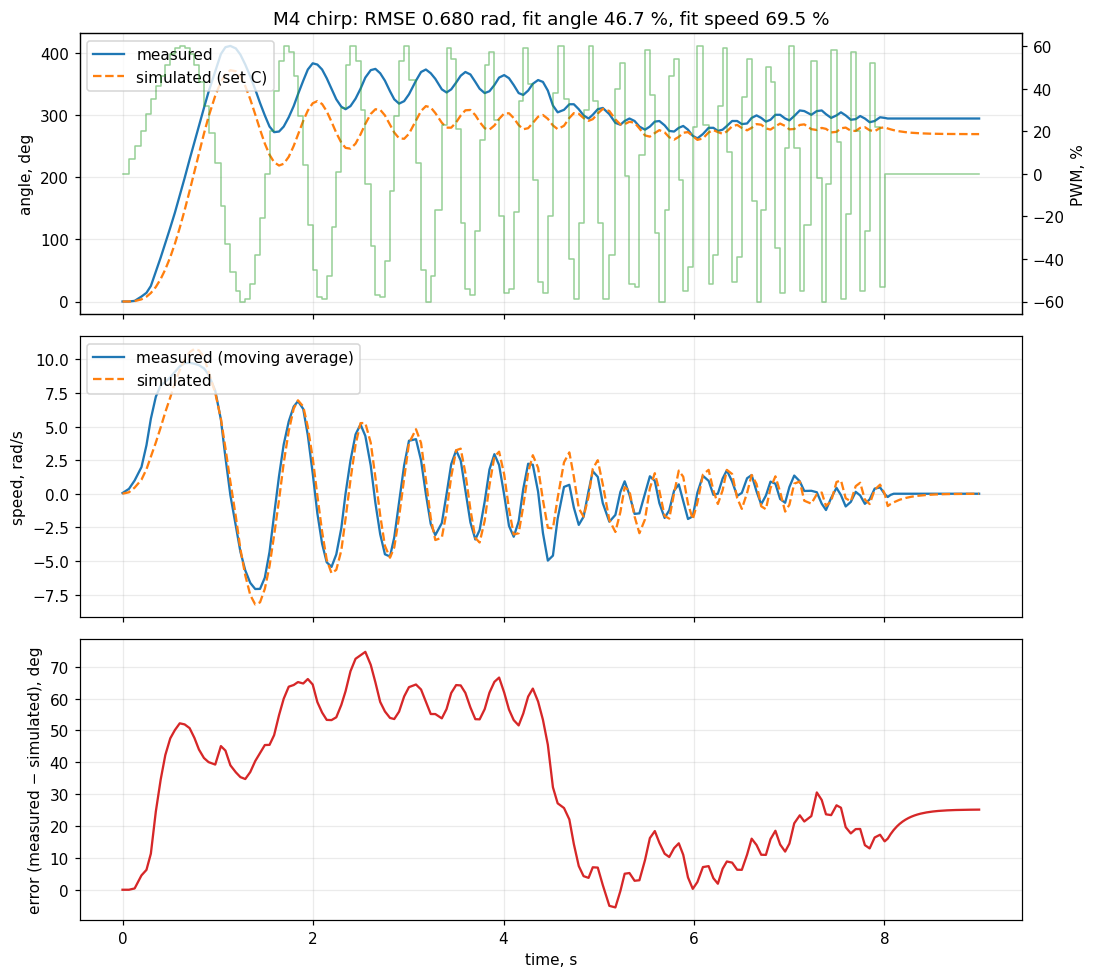

In [9]:
plot_signal("M4", "chirp", "C")

*Figure 5. Chirp, motor M4 (set C, fitted on the square wave only): angle, speed, PWM and error.*

### Chirp: speed amplitude against frequency

For each half-cycle of the chirp (between two zero crossings of the PWM) the local frequency is $f=1/(2\,\Delta t_{half})$ and the amplitude ratio is the peak of the smoothed speed divided by the peak PWM. The model prediction is $\mathrm{gain}/\sqrt{1+(2\pi f T_m)^2}$ (rad/s per % PWM).

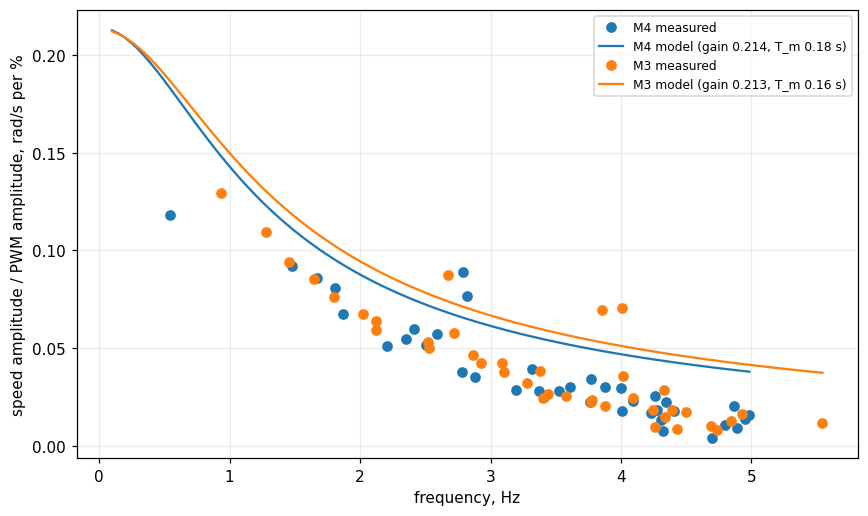

In [10]:
def chirp_response(m):
    run = RUNS[m]["chirp"]; t, p = run["t"], run["pwm"]
    v = np.abs(meas_speed(run))
    act = np.where(p != 0)[0]; last = act[-1]
    s = np.sign(p[:last + 1]); idx = [i for i in range(1, last + 1) if s[i] != 0 and s[i - 1] != 0 and s[i] != s[i - 1]]
    tc = [t[i - 1] + (t[i] - t[i - 1]) * (0 - p[i - 1]) / (p[i] - p[i - 1]) for i in idx]
    f, ratio = [], []
    for a, b in zip(tc[:-1], tc[1:]):
        half = b - a
        sel = (t >= a) & (t <= b + 0.5 * half)
        pk_p = np.abs(p[(t >= a) & (t <= b)]).max()
        if pk_p > 0 and sel.sum() > 1:
            f.append(1 / (2 * half)); ratio.append(v[sel].max() / pk_p)
    return np.array(f), np.array(ratio)

fig, ax = plt.subplots(figsize=(8, 4.8))
for m, c in (("M4", "C0"), ("M3", "C1")):
    f, r = chirp_response(m)
    g, T, _ = PARAMS[(m, "C")]
    ax.plot(f, r, "o", color=c, label=f"{m} measured")
    ff = np.linspace(0.1, max(f.max(), 3), 100)
    ax.plot(ff, g / np.sqrt(1 + (2 * np.pi * ff * T) ** 2), "-", color=c, label=f"{m} model (gain {g:.3f}, T_m {T:.2f} s)")
ax.set_xlabel("frequency, Hz"); ax.set_ylabel("speed amplitude / PWM amplitude, rad/s per %"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

*Figure 6. Amplitude ratio against frequency for the chirp, measured per half-cycle and predicted by the model. At high frequency the sampling (about 20 Hz) and the 3-sample smoothing also reduce the measured amplitude.*

## 5. Artifacts

### 5.1 Zero drift and a consistent zero

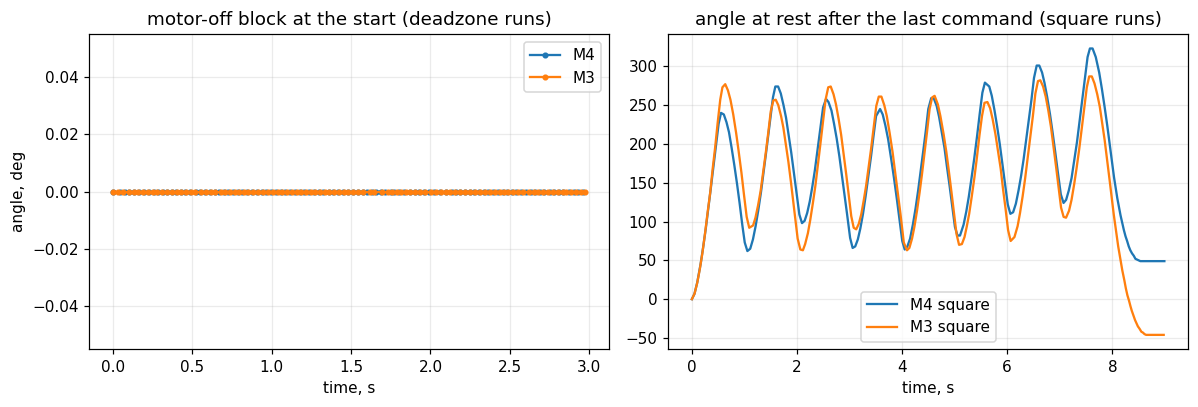

,Motor,"first time() stamp, ms","motor-off block, s","angle change in the block, deg","angle at the end of the run, deg"
0,M4,60.50,3.01,0.0,78.0
1,M3,58.17,3.02,0.0,-33.0


,Motor,run,"first time() stamp, ms","angle change in the last 0.7 s, deg","final angle, deg"
0,M4,square,69.73,-19.0,49.0
1,M4,chirp,99.55,0.0,295.0
2,M3,square,76.17,-51.0,-46.0
3,M3,chirp,61.93,0.0,229.0


In [11]:
rows, rest = [], []
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m, c in (("M4", "C0"), ("M3", "C1")):
    run = RUNS[m]["deadzone"]
    first = np.where(run["pwm"] != 0)[0][0]
    ax[0].plot(run["t"][:first], np.rad2deg(run["theta"][:first]), color=c, marker=".", label=m)
    rows.append({"Motor": m, "first time() stamp, ms": run["t0_ms"], "motor-off block, s": run["t"][first],
                 "angle change in the block, deg": np.rad2deg(run["theta"][first - 1] - run["theta"][0]),
                 "angle at the end of the run, deg": np.rad2deg(run["theta"][-1])})
    for sig in ("square", "chirp"):
        r = RUNS[m][sig]; tail = r["t"] > r["t"][-1] - 0.7
        rest.append({"Motor": m, "run": sig, "first time() stamp, ms": r["t0_ms"],
                     "angle change in the last 0.7 s, deg": np.rad2deg(r["theta"][tail][-1] - r["theta"][tail][0]),
                     "final angle, deg": np.rad2deg(r["theta"][-1])})
    r = RUNS[m]["square"]
    ax[1].plot(r["t"], np.rad2deg(r["theta"]), color=c, label=f"{m} square")
ax[0].set_title("motor-off block at the start (deadzone runs)"); ax[0].set_xlabel("time, s"); ax[0].set_ylabel("angle, deg"); ax[0].legend()
ax[1].set_title("angle at rest after the last command (square runs)"); ax[1].set_xlabel("time, s"); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(2)); display(pd.DataFrame(rest).round(2))

*Figure 7. Zero drift: the angle during the 3 s motor-off block, and the angle at rest at the end of the square runs.*

### 5.2 Coasting after power-off

In [12]:
rows = []
for m in ("M4", "M3"):
    run = RUNS[m]["deadzone"]; segs = segments(run)
    coast, pred = [], []
    for i, (pwm, a, b) in enumerate(segs):
        if pwm != 0 and i + 1 < len(segs) and segs[i + 1][0] == 0:
            a2, b2 = segs[i + 1][1], segs[i + 1][2]
            coast.append(abs(np.rad2deg(run["theta"][b2 - 1] - run["theta"][a2 - 1])))
            f = STEP_DATA[(m, pwm)]
            if f["ok"]: pred.append(abs(np.rad2deg(f["w_ss"] * f["T_m"])))
    rows.append({"Motor": m, "run": "deadzone (1 s coast after each level)", "mean coast angle, deg": np.mean(coast),
                 "model ω_ss·T_m, deg": np.mean(pred)})
    for sig in ("square", "chirp"):
        r = RUNS[m][sig]; k = np.where(r["pwm"] != 0)[0][-1]
        rows.append({"Motor": m, "run": f"{sig} (after the last command)",
                     "mean coast angle, deg": abs(np.rad2deg(r["theta"][-1] - r["theta"][k])), "model ω_ss·T_m, deg": np.nan})
display(pd.DataFrame(rows).round(1))

,Motor,run,"mean coast angle, deg","model ω_ss·T_m, deg"
0,M4,deadzone (1 s coast after each level),20.1,47.9
1,M4,square (after the last command),152.0,NaN
2,M4,chirp (after the last command),2.0,NaN
3,M3,deadzone (1 s coast after each level),28.6,84.7
4,M3,square (after the last command),197.0,NaN
5,M3,chirp (after the last command),2.0,NaN


### 5.3 Sampling jitter

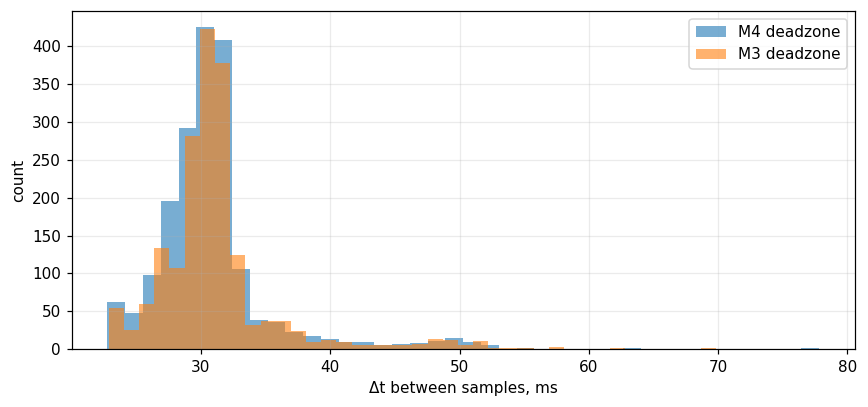

,Motor,run,"mean dt, ms","min dt, ms","max dt, ms","std dt, ms"
0,M4,deadzone,30.93,22.76,77.81,4.72
1,M4,square,48.33,25.52,83.08,8.67
2,M4,chirp,48.35,25.58,73.91,9.36
3,M3,deadzone,31.27,22.86,69.84,4.91
4,M3,square,46.51,24.29,73.68,8.58
5,M3,chirp,47.61,27.15,69.35,8.17


In [13]:
rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
for m in ("M4", "M3"):
    for sig in ("deadzone", "square", "chirp"):
        dt = 1000 * np.diff(RUNS[m][sig]["t"])
        rows.append({"Motor": m, "run": sig, "mean dt, ms": dt.mean(), "min dt, ms": dt.min(), "max dt, ms": dt.max(), "std dt, ms": dt.std()})
        if sig == "deadzone":
            ax.hist(dt, bins=40, alpha=.6, label=f"{m} deadzone")
ax.set_xlabel("Δt between samples, ms"); ax.set_ylabel("count"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).round(2))

*Figure 8. Histogram of the sampling interval in the dead-zone runs. The timer in the program is fixed, but writing to the file makes the real interval longer and not constant.*

### 5.4 Differentiation noise and encoder quantisation

In [14]:
rows = []
for m in ("M4", "M3"):
    run = RUNS[m]["deadzone"]
    raw_std, sm_std = [], []
    for pwm, a, b in segments(run):
        if pwm >= 6:                       # plateau levels, speed almost constant in the second half of the step
            h = a + (b - a) // 2
            v = np.gradient(run["theta"], run["t"])
            raw_std.append(v[h:b].std()); sm_std.append(smooth(v)[h + 1:b - 1].std())
    rows.append({"Motor": m, "speed noise, raw gradient, rad/s": np.mean(raw_std),
                 f"speed noise, {WIN}-sample average, rad/s": np.mean(sm_std),
                 "angle resolution, deg": 1.0, "speed resolution at mean dt, rad/s": np.deg2rad(1.0) / np.diff(run["t"]).mean()})
display(pd.DataFrame(rows).round(3))

,Motor,"speed noise, raw gradient, rad/s","speed noise, 3-sample average, rad/s","angle resolution, deg","speed resolution at mean dt, rad/s"
0,M4,0.192,0.105,1.0,0.564
1,M3,0.152,0.107,1.0,0.558


### 5.5 Direction reversals in the square wave

In [15]:
rows = []
for m in ("M4", "M3"):
    r = RUNS[m]["square"]; v = np.gradient(r["theta"], r["t"]); p = r["pwm"]; delays = []
    for k in range(1, len(p)):
        if p[k] != 0 and p[k - 1] != 0 and p[k] != p[k - 1]:
            j = k
            while j < len(p) - 1 and np.sign(smooth(v)[j]) == np.sign(p[k - 1]) :
                j += 1
            delays.append(r["t"][j] - r["t"][k])
    rows.append({"Motor": m, "reversals": len(delays), "mean delay until the speed changes sign, s": np.mean(delays),
                 "max, s": np.max(delays), "T_m (set C), s": PARAMS[(m, "C")][1]})
display(pd.DataFrame(rows).round(3))

,Motor,reversals,"mean delay until the speed changes sign, s","max, s","T_m (set C), s"
0,M4,15,0.104,0.131,0.177
1,M3,15,0.101,0.122,0.161


### 5.6 Forward vs backward asymmetry and motor-to-motor spread

In [16]:
rows = []
for m in ("M4", "M3"):
    f, b = TABLE[m].iloc[0], TABLE[m].iloc[1]
    rows.append({"Motor": m, "slope fwd": f["Slope, rad/s per % PWM"], "slope bwd": b["Slope, rad/s per % PWM"],
                 "slope diff, %": 100 * (f["Slope, rad/s per % PWM"] - b["Slope, rad/s per % PWM"]) / b["Slope, rad/s per % PWM"],
                 "T_m fwd, s": f["Mean T_m, s"], "T_m bwd, s": b["Mean T_m, s"],
                 "T_m diff, %": 100 * (f["Mean T_m, s"] - b["Mean T_m, s"]) / b["Mean T_m, s"]})
display(pd.DataFrame(rows).round(3))

mean = lambda m, col: TABLE[m][col].abs().mean()
spread = pd.DataFrame([{"quantity": c, "M4": mean("M4", c), "M3": mean("M3", c),
                        "M3 relative to M4, %": 100 * (mean("M3", c) - mean("M4", c)) / mean("M4", c)}
                       for c in ("Slope, rad/s per % PWM", "k_e, V·s/rad", "Mean T_m, s")])
display(spread.round(3))

,Motor,slope fwd,slope bwd,"slope diff, %","T_m fwd, s","T_m bwd, s","T_m diff, %"
0,M4,0.26,0.192,35.736,0.308,0.310,-0.59
1,M3,0.34,0.352,-3.468,0.495,0.471,5.26


,quantity,M4,M3,"M3 relative to M4, %"
0,"Slope, rad/s per % PWM",0.226,0.346,53.147
1,"k_e, V·s/rad",0.535,0.342,-36.184
2,"Mean T_m, s",0.309,0.483,56.349


## 6. Estimated values (report tables)

Table form required by the assignment, one table per motor (values computed above, from the dead-zone step levels).

In [17]:
for m in ("M4", "M3"):
    print(f"Motor {m}")
    display(TABLE[m].round(4).style.hide(axis="index"))

Motor M4


Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Forward,0.000000,0.260000,0.454000,0.307900,11.804400
Backward,0.000000,0.191500,0.616300,0.309800,11.804400


Motor M3


Direction,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Forward,0.000000,0.339600,0.347500,0.495300,11.804400
Backward,0.000000,0.351900,0.335500,0.470500,11.804400


## 7. Numbers for the analysis

In [18]:
print("Fit % on the complex signals (set C = fitted on the square wave):")
display(RESULTS[RESULTS["Set"].isin(["A", "C", "D"])][["Motor", "Set", "square fit angle, %", "square fit speed, %", "chirp fit angle, %", "chirp fit speed, %"]].round(1))
for m in ("M4", "M3"):
    print(f"{m}: gain from the 1-9 % levels (set A) = {PARAMS[(m, 'A')][0]:.3f} rad/s per %, gain that fits the ±60 % signals (set C) = {PARAMS[(m, 'C')][0]:.3f} rad/s per %")
for m in ("M4", "M3"):
    run = RUNS[m]["chirp"]; th, _ = simulate(run["t"], run["pwm"], *PARAMS[(m, "C")])
    e = np.rad2deg(run["theta"] - th); k = np.argmax(np.abs(e))
    print(f"{m} chirp: largest angle error {e[k]:.1f} deg at t = {run['t'][k]:.2f} s")
    run = RUNS[m]["square"]; th, _ = simulate(run["t"], run["pwm"], *PARAMS[(m, "C")])
    e = np.rad2deg(run["theta"] - th); k = np.argmax(np.abs(e))
    print(f"{m} square: largest angle error {e[k]:.1f} deg at t = {run['t'][k]:.2f} s")

Fit % on the complex signals (set C = fitted on the square wave):


,Motor,Set,"square fit angle, %","square fit speed, %","chirp fit angle, %","chirp fit speed, %"
0,M4,A,50.8,52.6,60.0,56.7
2,M4,C,60.0,70.6,46.7,69.5
3,M4,D,57.0,66.2,69.5,67.8
4,M3,A,-12.5,44.0,-204.1,48.0
6,M3,C,73.0,76.4,11.1,68.8
7,M3,D,69.7,80.5,22.7,68.8


M4: gain from the 1-9 % levels (set A) = 0.226 rad/s per %, gain that fits the ±60 % signals (set C) = 0.214 rad/s per %
M3: gain from the 1-9 % levels (set A) = 0.346 rad/s per %, gain that fits the ±60 % signals (set C) = 0.213 rad/s per %
M4 chirp: largest angle error 74.7 deg at t = 2.55 s
M4 square: largest angle error 72.5 deg at t = 7.37 s
M3 chirp: largest angle error -116.3 deg at t = 8.05 s
M3 square: largest angle error 54.5 deg at t = 7.27 s


## 8. Analysis (my own words)

**8.1 How well does the first-order model with constant T_m and k_e describe the motor?**  
_Write one paragraph. Use: the fit % of angle and speed on square and chirp (Section 7), where the error is largest (Section 7 and Figures 4–5), whether T_m was constant over PWM (Figure 3)._

**8.2 Forward vs backward rotation: same motor? One parameter set or two?**  
_Write one paragraph. Use: the slope, dead zone and T_m differences in % (Section 5.6) and the two tables in Section 6._

**8.3 Which artifacts did I find, how big are they, which matter for odometry?**  
_Write one paragraph. Use: zero drift (5.1), coasting (5.2), sampling jitter (5.3), differentiation noise (5.4), reversal delay (5.5), motor-to-motor spread (5.6), and the speed plateaus visible in Figure 2._

**8.4 Which complex signal did I choose and what did it show that the step series did not?**  
_Write one paragraph. Use: square wave (repeated accelerations and reversals), chirp (frequency response, Figure 6), and the model comparison in Section 4._